# Características acústicas — hito 2

**Trabajo Final IA I 2026 · UNCUYO**

Un vector de 160 componentes por audio procesado.
No se ajustan escaladores, PCA o K-NN. No se reproducen ni incrustan WAV.

Primero ejecutar `src/extraer_dataset_audio.py --verificar-repetibilidad`
desde el entorno `.venv`. Después ejecutar estas celdas en orden.

Las ventanas acústicas tienen 25 ms y avanzan 10 ms.
Los diez segmentos representan posiciones relativas dentro de la palabra.
Son conceptos distintos.

La documentación completa está en
`documentos/etapas/caracteristicas_audio_hito2.md`.

## Qué significa convertir un audio en un vector

Un WAV contiene miles de valores de amplitud. Dos pronunciaciones de la misma
palabra no duran exactamente lo mismo y no pueden compararse muestra por muestra.
El extractor resume cada grabación mediante una lista ordenada:

$$\mathbf{x}_{audio}=[x_1,x_2,\ldots,x_{160}].$$

Cada posición conserva el mismo significado para todas las grabaciones. El
comando, el hablante, el identificador y la partición permanecen en el catálogo;
no se incorporan a $X$ como características.

El proceso seguido es:

1. Tomar el WAV ya preprocesado y sus límites de actividad.
2. Analizar fragmentos cortos mediante ventanas acústicas.
3. Asignar cada ventana a una de diez posiciones relativas de la palabra.
4. Calcular ZCR, amplitud y MFCC en cada ventana.
5. Resumir las ventanas de cada segmento y concatenar los resultados.

Así se obtiene una dimensión fija sin estirar la palabra.


In [7]:
from pathlib import Path
from collections import Counter
import csv
import json
import sys
import importlib.metadata

import numpy as np
import matplotlib.pyplot as plt

RAIZ = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "config/caracteristicas_audio_v1.json").exists()
    ),
    None,
)
if RAIZ is None:
    raise FileNotFoundError("Abrí el notebook dentro del repositorio.")

if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))

from caracteristicas_audio import (
    cargar_config, nombres_caracteristicas, extraer_audio,
    limites_desde_detalle, banco_mel,
)
from preprocesamiento_audio import leer_wav_pcm16, a_flotante
from extraer_dataset_audio import leer_json, sha, sha_codigo

SALIDA_RELATIVA = ""  # Opcional: ruta exacta de una ejecución.
cfg = cargar_config()

if SALIDA_RELATIVA:
    SALIDA = RAIZ / SALIDA_RELATIVA
else:
    activo = leer_json(RAIZ / "datos/audio/procesados/actual.json")
    deps = {
        p: importlib.metadata.version(p)
        for p in ("numpy", "scipy")
    }
    candidatos = []
    for p in (RAIZ / "datos/caracteristicas/audio").glob(
        "*/ejecucion_*/manifiesto.json"
    ):
        if p.parent.name.endswith(".parcial"):
            continue
        c = leer_json(p)["contrato"]
        if (
            c["config"] == cfg
            and c["dependencias"] == deps
            and c["version_preprocesamiento"] == activo["version"]
            and all(
                sha_codigo(RAIZ / "src" / n) == digest
                for n, digest in c["codigo"].items()
            )
        ):
            candidatos.append(p.parent)

    if not candidatos:
        raise FileNotFoundError(
            "Ejecutá primero el extractor con el código actual."
        )
    if len({p.parent.name for p in candidatos}) != 1:
        raise ValueError("Indicar SALIDA_RELATIVA explícitamente.")
    SALIDA = sorted(candidatos, key=lambda p: p.name)[-1]

manifest = leer_json(SALIDA / "manifiesto.json")
resumen = leer_json(SALIDA / "resumen.json")
cfg = leer_json(SALIDA / "config_efectiva.json")

with (SALIDA / "catalogo_caracteristicas.csv").open(
    encoding="utf-8-sig", newline=""
) as f:
    filas = list(csv.DictReader(f))

with np.load(SALIDA / "vectores.npz", allow_pickle=False) as datos:
    X = datos["X"].copy()
    ids = datos["muestras"].copy()
    nombres = datos["nombres"].copy()

print("Ejecución:", SALIDA.relative_to(RAIZ))
print(json.dumps(resumen, ensure_ascii=False, indent=2))

Ejecución: datos\caracteristicas\audio\audio_segmentos_v1_1caab0e82325\ejecucion_20261020T191828_653873Z
{
  "id_extractor": "audio_segmentos_v1_1caab0e82325",
  "ejecucion": "ejecucion_20261020T191828_653873Z",
  "version_preprocesamiento": "audio_preprocesamiento_v1_3f3a7a105289",
  "total_catalogo": 180,
  "estados": {
    "vectorizada": 180
  },
  "forma_X": [
    180,
    160
  ],
  "valores_finitos": true,
  "decisiones_revision": {
    "pendiente": 179,
    "conservar": 1
  },
  "particiones": {
    "sin_asignar": 180
  },
  "hablantes": 6,
  "vectorizadas_por_comando": {
    "reconocer": 60,
    "identificar": 60,
    "salir": 60
  },
  "muestras_con_avisos_extractor": 13,
  "vectorizadas_con_avisos_previos": 28,
  "verificadas_repetibilidad": 180,
  "diferencia_max_repeticion": 0.0,
  "salida": "datos/caracteristicas/audio/audio_segmentos_v1_1caab0e82325/ejecucion_20261020T191828_653873Z",
  "nota": "Vectorizable no implica revisión humana aprobada ni habilitación para modelad

## Correspondencia e integridad

`X` contiene solo características. Los identificadores están separados.

El catálogo también conserva filas excluidas, fallidas o diferidas.
Por eso se utiliza `fila_vector` y se comprueba el identificador, en lugar
de asumir que todas las filas del catálogo corresponden a filas de X.

In [8]:
for nombre, digest in manifest["sha256_archivos"].items():
    assert sha(SALIDA / nombre) == digest, nombre

assert X.shape == (len(ids), len(nombres))
assert np.isfinite(X).all()
assert len(set(ids)) == len(ids)
assert nombres.tolist() == nombres_caracteristicas(cfg)
assert X.shape[1] == cfg["segmentos"] * (
    4 + 3 * len(cfg["indices_mfcc"])
)

with (SALIDA / "catalogo_origen.csv").open(
    encoding="utf-8-sig", newline=""
) as f:
    origen = {r["muestra_id"]: r for r in csv.DictReader(f)}

indices = []
for r in filas:
    for campo, valor in origen[r["muestra_id"]].items():
        assert r[campo] == valor, (r["muestra_id"], campo)

    if r["estado_extraccion"] == "vectorizada":
        k = int(r["fila_vector"])
        assert ids[k] == r["muestra_id"]
        indices.append(k)
    else:
        assert r["fila_vector"] == ""

assert sorted(indices) == list(range(len(ids)))

print("Integridad, dimensión, finitud y correspondencia: OK")
print("Forma:", X.shape)
print("Revisión:", dict(Counter(r["decision_revision"] for r in filas)))
print("Particiones:", dict(Counter(r["particion"] for r in filas)))

Integridad, dimensión, finitud y correspondencia: OK
Forma: (180, 160)
Revisión: {'pendiente': 179, 'conservar': 1}
Particiones: {'sin_asignar': 180}


## Una palabra y sus segmentos

Se elige un ejemplo de H001, ya utilizado en desarrollo.
Los márgenes del WAV se muestran en gris; los diez segmentos dividen
el intervalo de actividad estimado por el preprocesamiento.

Los márgenes aportan contexto a las ventanas de los extremos.
No se recorta ni se estira otra vez la grabación.

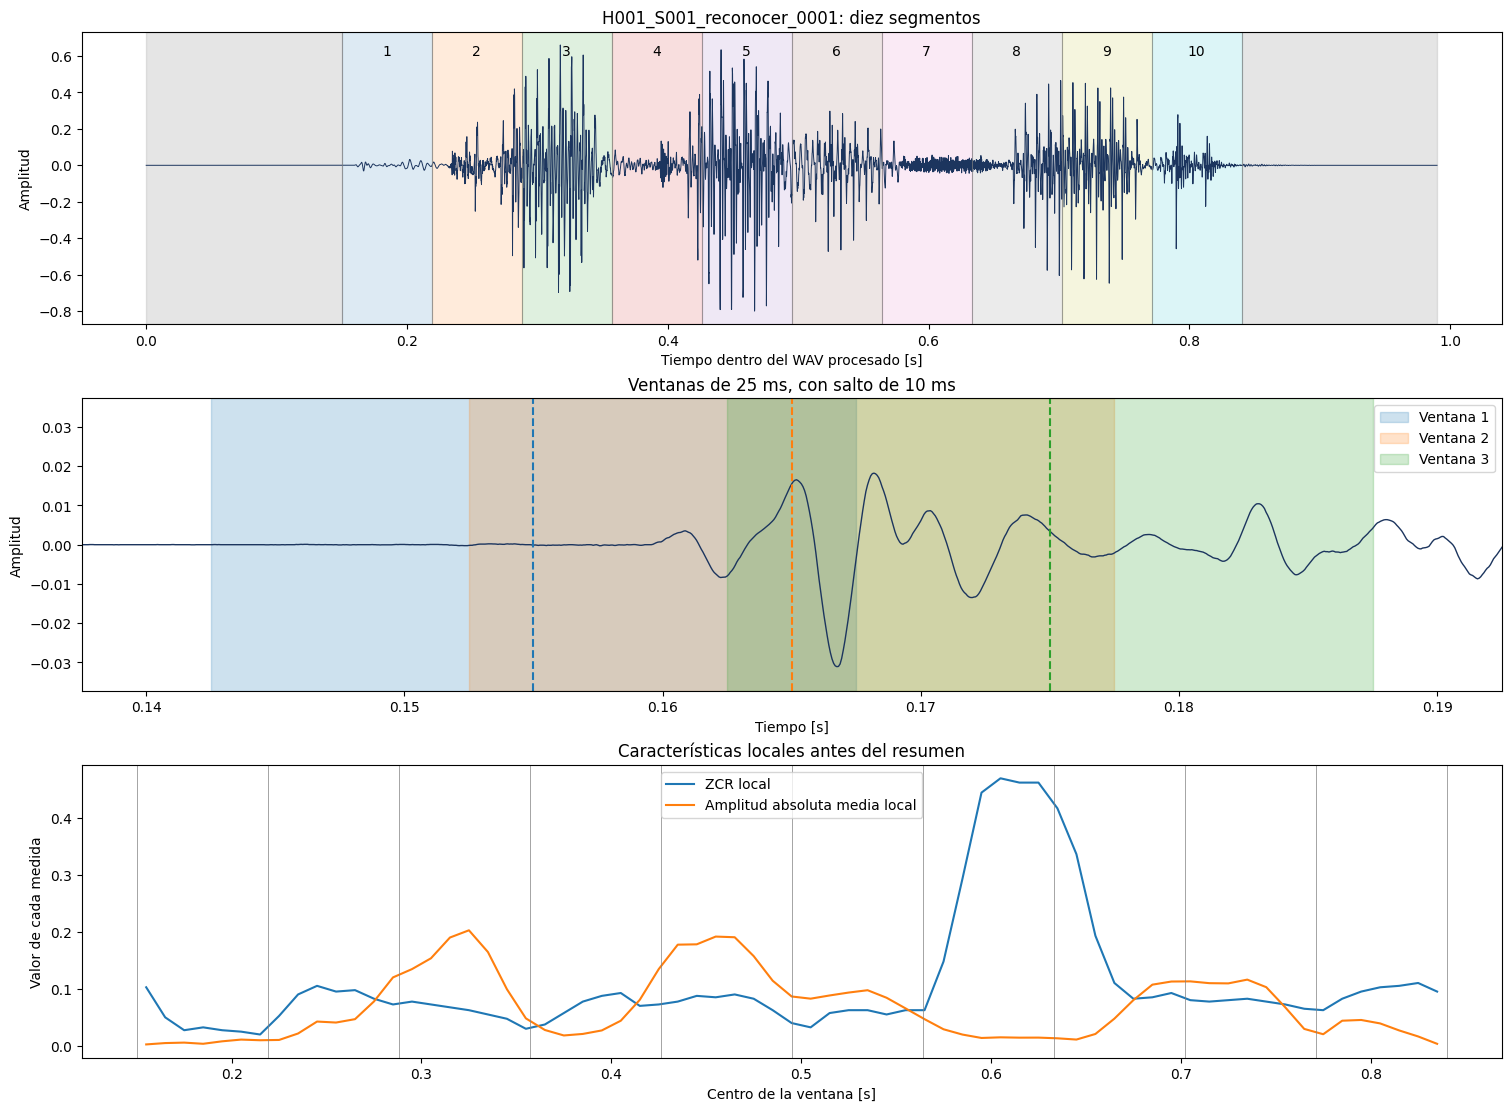

Actividad: 0.69 s
Ventanas: 69
Por segmento: [7, 7, 7, 7, 6, 7, 7, 7, 7, 7]
Avisos: []


In [9]:
HABLANTE_EJEMPLO = "H001"
COMANDO_EJEMPLO = "reconocer"

elegibles = [
    r for r in filas
    if r["hablante"] == HABLANTE_EJEMPLO
    and r["comando"] == COMANDO_EJEMPLO
    and r["estado_extraccion"] == "vectorizada"
    and r["particion"] != "prueba"
]
if not elegibles:
    raise ValueError("Elegí un ejemplo disponible de desarrollo.")

r = sorted(elegibles, key=lambda r: r["muestra_id"])[0]
assert sha(RAIZ / r["ruta_procesada"]) == r["sha256_procesado"]
assert sha(RAIZ / r["ruta_detalle"]) == r["sha256_detalle_leido"]

audio, fs = leer_wav_pcm16(RAIZ / r["ruta_procesada"])
detalle = leer_json(RAIZ / r["ruta_detalle"])["detalle"]
limites = limites_desde_detalle(detalle, fs, len(audio))

v, info, local = extraer_audio(
    audio, fs, limites, cfg, devolver_intermedios=True
)
np.testing.assert_allclose(
    v, X[int(r["fila_vector"])], atol=1e-12, rtol=1e-12
)

x = a_flotante(audio)[:, 0]
t = np.arange(len(x)) / fs
bordes = np.asarray(info["bordes_segmentos_s"])
centros = local["centros_s"]
colores = plt.get_cmap("tab10")

fig, ax = plt.subplots(
    3, 1, figsize=(15, 11), constrained_layout=True
)
ax[0].plot(t, x, color="#1c355e", linewidth=0.7)

for s, (a, b) in enumerate(zip(bordes[:-1], bordes[1:])):
    ax[0].axvspan(a, b, color=colores(s % 10), alpha=0.15)
    ax[0].text(
        (a + b) / 2, 0.92, str(s + 1),
        transform=ax[0].get_xaxis_transform(), ha="center"
    )
for b in bordes:
    ax[0].axvline(b, color="gray", linewidth=0.5)
ax[0].axvspan(0, bordes[0], color="gray", alpha=0.2)
ax[0].axvspan(bordes[-1], len(x) / fs, color="gray", alpha=0.2)
ax[0].set_title(r["muestra_id"] + ": diez segmentos")
ax[0].set_xlabel("Tiempo dentro del WAV procesado [s]")
ax[0].set_ylabel("Amplitud")

mitad = info["ventana_muestras"] / fs / 2
ax[1].plot(t, x, color="#1c355e", linewidth=1)

for k, centro in enumerate(centros[:3]):
    ax[1].axvspan(
        centro - mitad, centro + mitad,
        color=colores(k), alpha=0.22, label=f"Ventana {k + 1}"
    )
    ax[1].axvline(centro, color=colores(k), linestyle="--")

lo = max(0, centros[0] - mitad - 0.005)
hi = centros[min(2, len(centros) - 1)] + mitad + 0.005
ax[1].set_xlim(lo, hi)
zoom = (t >= lo) & (t <= hi)
lim_y = max(float(np.max(np.abs(x[zoom]))) * 1.2, 1e-5)
ax[1].set_ylim(-lim_y, lim_y)
ax[1].set_title("Ventanas de 25 ms, con salto de 10 ms")
ax[1].set_xlabel("Tiempo [s]")
ax[1].set_ylabel("Amplitud")
ax[1].legend()

ax[2].plot(centros, local["zcr"], label="ZCR local")
ax[2].plot(
    centros, local["amplitud_media"],
    label="Amplitud absoluta media local"
)
for b in bordes:
    ax[2].axvline(b, color="gray", linewidth=0.5)
ax[2].set_title("Características locales antes del resumen")
ax[2].set_xlabel("Centro de la ventana [s]")
ax[2].set_ylabel("Valor de cada medida")
ax[2].legend()
plt.show()

print("Actividad:", info["duracion_actividad_s"], "s")
print("Ventanas:", info["ventanas"])
print("Por segmento:", info["ventanas_por_segmento"])
print("Avisos:", info["avisos"])

## MFCC: descripción del espectro

En cada ventana: Hann, FFT, potencia, filtros Mel, logaritmo natural y DCT.
Se eligen los órdenes c1, c2, c4 y c5, índices `[1,2,4,5]`.

Los MFCC describen aspectos de la forma del espectro.
No representan probabilidades de comandos y pueden ser negativos.
Las convenciones completas están en el documento y el manifiesto.

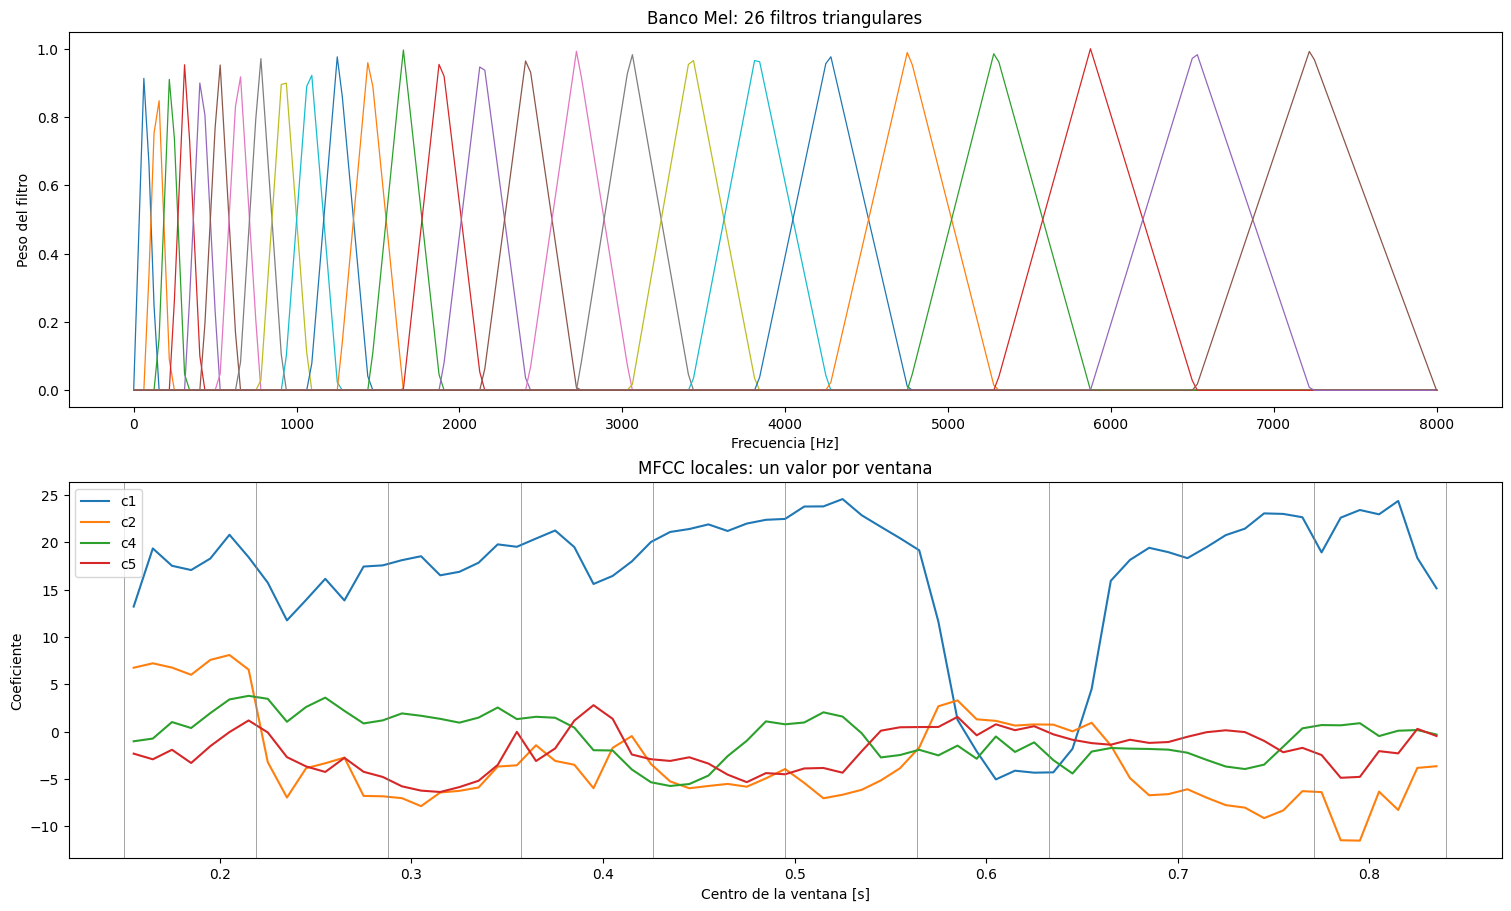

In [10]:
B, frecuencias, nodos = banco_mel(cfg)
fig, ax = plt.subplots(
    2, 1, figsize=(15, 9), constrained_layout=True
)

for filtro in B:
    ax[0].plot(frecuencias, filtro, linewidth=0.9)
ax[0].set_title("Banco Mel: 26 filtros triangulares")
ax[0].set_xlabel("Frecuencia [Hz]")
ax[0].set_ylabel("Peso del filtro")

for j, k in enumerate(cfg["indices_mfcc"]):
    ax[1].plot(centros, local["mfcc"][:, j], label=f"c{k}")
for b in bordes:
    ax[1].axvline(b, color="gray", linewidth=0.5)
ax[1].set_title("MFCC locales: un valor por ventana")
ax[1].set_xlabel("Centro de la ventana [s]")
ax[1].set_ylabel("Coeficiente")
ax[1].legend()
plt.show()

## Vector final

Por segmento guardamos 16 valores, siempre con el mismo orden.
Los números de distintos tipos tienen escalas diferentes:
el escalador se ajustará posteriormente, solo con entrenamiento.

El siguiente ejemplo muestra las características del primer segmento
y la evolución de algunos resúmenes a lo largo de la palabra.

s01_zcr_media                  0.04081633
s01_zcr_max                    0.10275689
s01_amplitud_abs_media         0.00668340
s01_amplitud_abs_max           0.03228760
s01_mfcc_c1_media              17.79472738
s01_mfcc_c1_max                20.78244230
s01_mfcc_c1_std                2.19303892
s01_mfcc_c2_media              6.98429700
s01_mfcc_c2_max                8.08537196
s01_mfcc_c2_std                0.64223884
s01_mfcc_c4_media              1.24570625
s01_mfcc_c4_max                3.77074235
s01_mfcc_c4_std                1.74884341
s01_mfcc_c5_media              -1.56107321
s01_mfcc_c5_max                1.17226609
s01_mfcc_c5_std                1.48461841


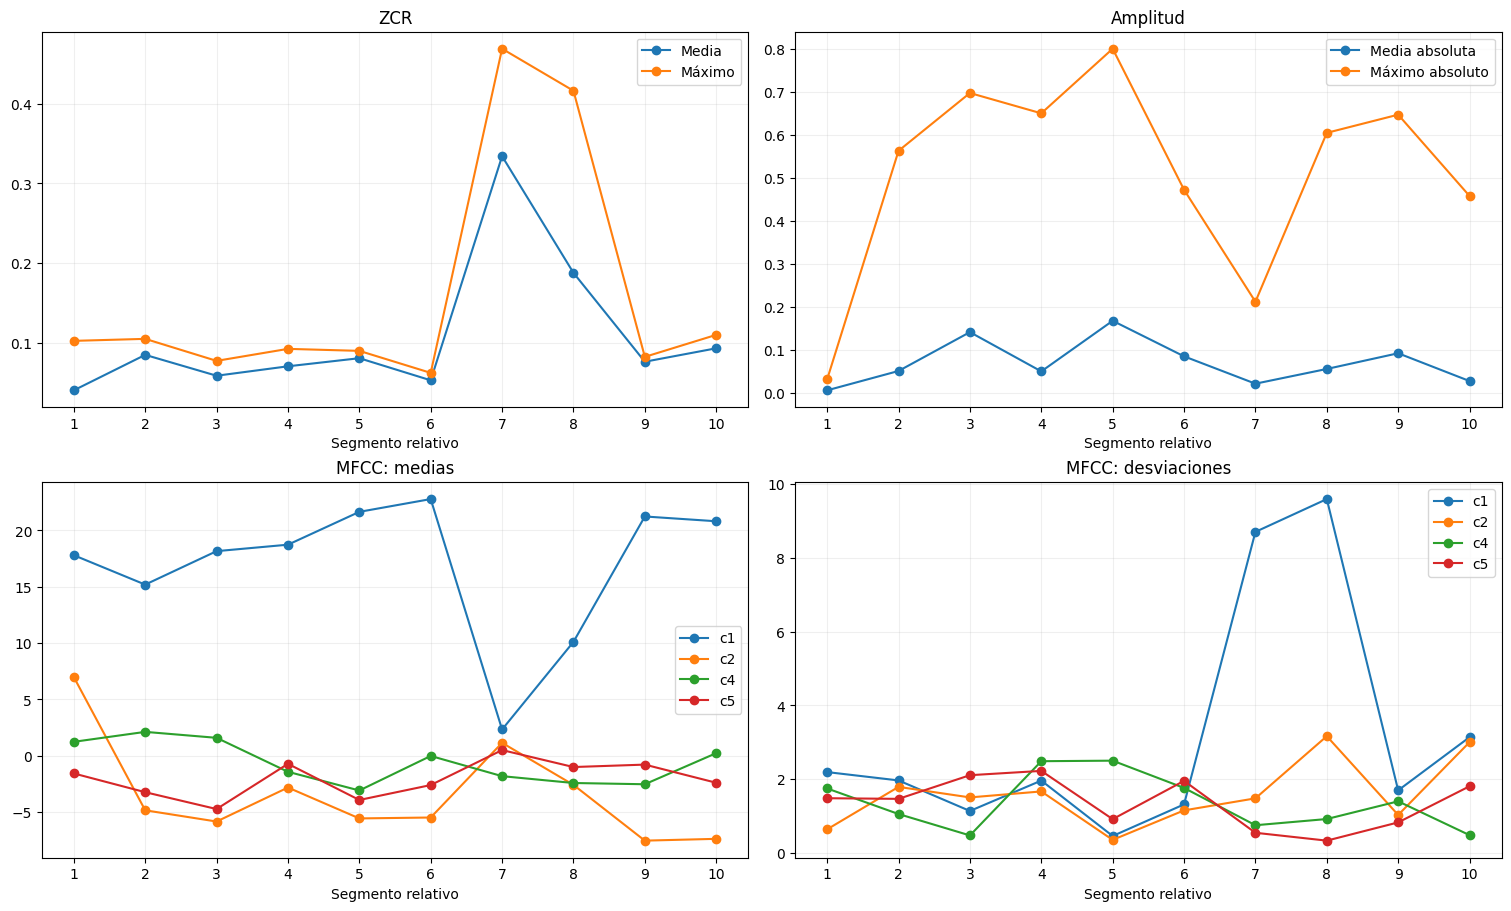

Vector final: (160,)
Todos finitos: True


In [11]:
cantidad_local = 4 + 3 * len(cfg["indices_mfcc"])
for nombre, valor in zip(
    nombres[:cantidad_local], v[:cantidad_local]
):
    print(f"{nombre:30s} {valor:.8f}")

por_segmento = v.reshape(cfg["segmentos"], cantidad_local)
ss = np.arange(1, cfg["segmentos"] + 1)

fig, ax = plt.subplots(
    2, 2, figsize=(15, 9), constrained_layout=True
)
ax[0, 0].plot(ss, por_segmento[:, 0], "-o", label="Media")
ax[0, 0].plot(ss, por_segmento[:, 1], "-o", label="Máximo")
ax[0, 0].set_title("ZCR")

ax[0, 1].plot(
    ss, por_segmento[:, 2], "-o", label="Media absoluta"
)
ax[0, 1].plot(
    ss, por_segmento[:, 3], "-o", label="Máximo absoluto"
)
ax[0, 1].set_title("Amplitud")

for j, k in enumerate(cfg["indices_mfcc"]):
    ax[1, 0].plot(
        ss, por_segmento[:, 4 + 3*j], "-o", label=f"c{k}"
    )
    ax[1, 1].plot(
        ss, por_segmento[:, 6 + 3*j], "-o", label=f"c{k}"
    )
ax[1, 0].set_title("MFCC: medias")
ax[1, 1].set_title("MFCC: desviaciones")

for a in ax.flat:
    a.set_xlabel("Segmento relativo")
    a.set_xticks(ss)
    a.grid(alpha=0.2)
    a.legend()
plt.show()

print("Vector final:", v.shape)
print("Todos finitos:", np.isfinite(v).all())

## Registro validado de la ejecución con 180 audios

El 20/10/2026 se ejecutaron primero las 13 pruebas automáticas: todas terminaron
en `OK`. La extracción posterior utilizó Windows 11, Python 3.14.0, NumPy 2.3.5
y SciPy 1.17.0.

| Control | Resultado |
|---|---:|
| Grabaciones del catálogo | 180 |
| Hablantes | 6 |
| Reconocer / identificar / salir | 60 / 60 / 60 |
| Forma de $X$ | $180\times160$ |
| Valores finitos | Sí |
| Diferencia máxima al repetir | 0.0 |
| Muestras con avisos del extractor | 13 |
| Muestras con avisos previos | 28 |
| Decisiones humanas | 179 pendiente, 1 conservar |
| Particiones | 180 sin asignar |

Se comprobaron los hashes del manifiesto, la correspondencia entre IDs y filas,
el orden de las 160 columnas y la igualdad exacta entre `vectores.csv` y
`vectores.npz`. No aparecieron columnas constantes.

De los 13 avisos nuevos, 12 indican que una o más ventanas fueron casi
silenciosas. Esto puede ocurrir por pausas o partes débiles dentro de la palabra.
El aviso restante corresponde a `H002_S001_identificar_0009`: una ventana de
borde necesitó ceros fuera del WAV para conservar sus 25 ms. Tres muestras tienen
avisos de ambas etapas, por lo que 13 y 28 no se suman como grupos distintos.

Todas pudieron vectorizarse. Los avisos permanecen visibles para revisión y no
se utilizaron para modificar parámetros hasta obtener un resultado favorable.


## Revisión y estado para modelado

`Vectorizada` significa que se pudo construir un vector finito con el orden
esperado. Todavía se necesitan una decisión humana y una partición para saber si
esa muestra puede entrar al modelado. Los avisos del preprocesamiento y del
extractor se conservan por separado.

Se decidió utilizar H006 para entrenamiento, ya que se prevé conseguir hablantes
nuevos para la evaluación final. Esta intención todavía no modifica el catálogo:
se aplicará mediante un mapa persistente, junto con la asignación de los demás
hablantes, antes de ajustar escaladores o PCA. H001 y H002 participaron del
desarrollo y no se presentarán como prueba final independiente.

La ejecución de este notebook demuestra extracción, integridad y repetibilidad.
Todavía no mide reconocimiento de comandos.


In [12]:
for rr in filas:
    if rr["particion"] == "prueba":
        continue
    nuevos = json.loads(rr["avisos_extraccion_json"])
    if nuevos or rr["estado_extraccion"] != "vectorizada":
        print(
            rr["muestra_id"],
            rr["estado_extraccion"],
            nuevos,
            rr["motivo_extraccion"],
            sep=" | ",
        )

print(
    "Estados para modelado:",
    dict(Counter(r["estado_para_modelado"] for r in filas)),
)
print("No se ajustaron escaladores, PCA ni K-NN.")

H001_S001_reconocer_0003 | vectorizada | ['ventanas_casi_silenciosas:4'] | 
H001_S001_identificar_0001 | vectorizada | ['ventanas_casi_silenciosas:9'] | 
H001_S001_identificar_0010 | vectorizada | ['ventanas_casi_silenciosas:1'] | 
H001_S001_salir_0007 | vectorizada | ['ventanas_casi_silenciosas:8'] | 
H002_S001_identificar_0009 | vectorizada | ['contexto_fuera_del_wav_completado_con_ceros'] | 
H003_S001_salir_0009 | vectorizada | ['ventanas_casi_silenciosas:2'] | 
H004_S001_identificar_0003 | vectorizada | ['ventanas_casi_silenciosas:1'] | 
H005_S001_salir_0002 | vectorizada | ['ventanas_casi_silenciosas:6'] | 
H006_S001_reconocer_0005 | vectorizada | ['ventanas_casi_silenciosas:21'] | 
H006_S001_reconocer_0007 | vectorizada | ['ventanas_casi_silenciosas:7'] | 
H006_S001_reconocer_0010 | vectorizada | ['ventanas_casi_silenciosas:1'] | 
H006_S001_identificar_0009 | vectorizada | ['ventanas_casi_silenciosas:22'] | 
H006_S001_salir_0005 | vectorizada | ['ventanas_casi_silenciosas:24'] | 

## Cómo se utilizará este vector con K-NN

Después de definir las particiones, el escalador aprenderá sus parámetros solo
con entrenamiento. Para reconocer una grabación nueva se aplicarán el mismo
preprocesamiento, extractor, orden de columnas y escalador.

K-NN buscará los $K$ vectores de entrenamiento más cercanos y decidirá entre
`reconocer`, `identificar` y `salir` usando sus etiquetas. La validación permitirá
elegir $K$ y comprobar el desempeño con hablantes separados.

El clasificador siempre puede elegir alguna de las tres clases. Rechazar una
palabra diferente requerirá una evaluación y una regla adicional; no se puede
fijar un umbral confiable solo porque la extracción funcione.

PCA se usará primero como herramienta de exploración. Un gráfico con dos
componentes puede mostrar tendencias o superposiciones, pero no garantiza que
las palabras sean separables y no obliga a reducir el futuro K-NN a dos números.
